# Synthetic Financial (PaySim): Data Quality and EDA

**Question:** Can we identify simulated mobile-money fraud from what is known before authorizing a transaction?
This notebook checks the raw file, describes the imbalance and transaction patterns, and records which fields are safe to use. It does not fit a model or modify the source CSV.

Sources: [PaySim dataset and field definitions](https://www.kaggle.com/datasets/ealaxi/paysim1) and
[PaySim simulator paper](https://www.msc-les.org/proceedings/emss/2016/EMSS2016_249.pdf).
Monetary values are in the dataset's local currency, not explicitly USD.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.synthetic_financial import BALANCE_COLUMNS, load_paysim, paysim_path

DEVELOPMENT_END = 14 * 24
path = paysim_path(PROJECT_ROOT)
df = load_paysim(path)
print(f"Source: {path.relative_to(PROJECT_ROOT)}")
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
print(f"Observed hours: {df['step'].min()} to {df['step'].max()} "
      f"({df['step'].nunique()} distinct steps)")

Source: data/raw/synthetic_financial/synthetic_financial.csv
Rows: 6,362,620; columns: 11
Observed hours: 1 to 743 (743 distinct steps)


## 1. Validate before cleaning

The loader checks the schema, required values, known transaction types, binary labels, and finite, non-negative amounts and balances. It fails on invalid input rather than silently dropping rows or substituting zeros. We audit *exact* duplicates over all raw columns; the file has no unique transaction ID, so matching rows would not automatically prove duplicate ingestion. We retain genuine zeros and extremes, and do not rebalance the dataset or write a separate cleaned CSV.

In [2]:
duplicate_rows = int(df.duplicated().sum())
column_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_rows": df.isna().sum(),
})
display(column_profile)
print(f"Exact duplicate rows beyond the first occurrence: {duplicate_rows:,}")

checks = {
    "Zero amount": df["amount"].eq(0),
    "Existing simulator flag": df["isFlaggedFraud"].eq(1),
    "Merchant destination (M prefix)": df["nameDest"].str.startswith("M"),
    "Merchant with both destination balances zero": (
        df["nameDest"].str.startswith("M")
        & df["oldbalanceDest"].eq(0) & df["newbalanceDest"].eq(0)
    ),
}
display(pd.DataFrame.from_records([
    {"check": label, "rows": int(mask.sum()), "fraud_rows": int(df.loc[mask, "isFraud"].sum())}
    for label, mask in checks.items()
]))
del checks

,dtype,missing_rows
step,int32,0
type,category,0
amount,float64,0
nameOrig,string,0
oldbalanceOrg,float64,0
newbalanceOrig,float64,0
nameDest,string,0
oldbalanceDest,float64,0
newbalanceDest,float64,0
isFraud,int8,0


Exact duplicate rows beyond the first occurrence: 0


,check,rows,fraud_rows
0,Zero amount,16,16
1,Existing simulator flag,16,16
2,Merchant destination (M prefix),2151495,0
3,Merchant with both destination balances zero,2151495,0


## 2. Measure rarity and check the time axis

The full-file summary describes the dataset, not a modeling result. Fraud-pattern exploration in the remaining sections is restricted to the first 14 simulated days, the modeling notebook's training window. Full-file transaction volume by day shows why a time split will not produce equal-sized partitions.

,class,transactions,share_pct
0,Not fraud,6354407,99.8709
1,Fraud,8213,0.1291


Non-fraud transactions per fraud transaction: 773.7


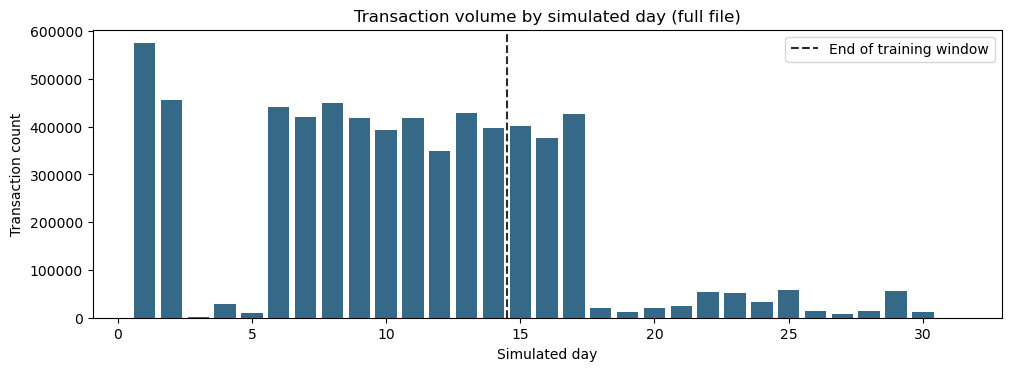

In [3]:
counts = df["isFraud"].value_counts().reindex([0, 1], fill_value=0)
distribution = pd.DataFrame({
    "class": ["Not fraud", "Fraud"],
    "transactions": counts.to_numpy(),
    "share_pct": (100 * counts / len(df)).to_numpy(),
})
display(distribution.round(4))
print(f"Non-fraud transactions per fraud transaction: {counts[0] / counts[1]:,.1f}")

volumes = df.groupby((df["step"] - 1) // 24 + 1).size()
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
ax.bar(volumes.index, volumes, color="#356987")
ax.axvline(14.5, color="#352530", linestyle="--", label="End of training window")
ax.set(title="Transaction volume by simulated day (full file)",
       xlabel="Simulated day", ylabel="Transaction count")
ax.legend()
plt.show()

## 3. Compare transaction types and amounts (training window)

Report counts beside rates: a common transaction type can produce more fraud events even if another type has a higher fraud rate. Use full training counts and within-class amount distributions. Zero fraud in a simulator category is not evidence that the same category is safe in production.

,transactions,fraud_cases,fraud_rate
type,,,
TRANSFER,396580,1874,0.004725
CASH_OUT,1694367,1893,0.001117
CASH_IN,1047668,0,0.000000
DEBIT,29926,0,0.000000
PAYMENT,1616234,0,0.000000


,Min,Median,90th percentile,99th percentile,Max
isFraud,,,,,
0,0.01,74957.83,364454.10,1515238.13,92445516.64
1,0.00,416284.70,3884664.38,10000000.00,10000000.00


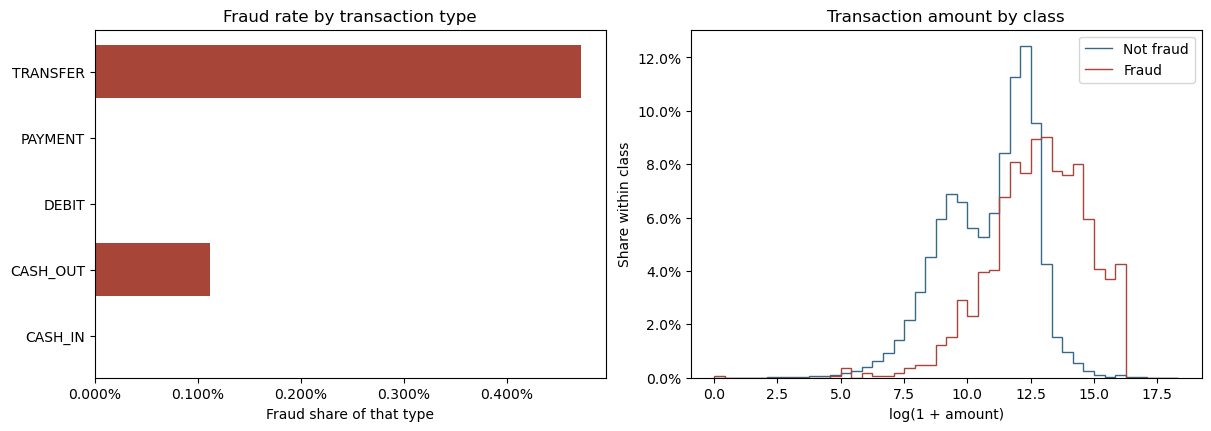

In [4]:
dev = df.loc[df["step"].le(DEVELOPMENT_END), ["type", "amount", *BALANCE_COLUMNS, "isFraud"]]
by_type = (dev.groupby("type", observed=True)["isFraud"]
           .agg(transactions="size", fraud_cases="sum"))
by_type["fraud_rate"] = by_type["fraud_cases"] / by_type["transactions"]
display(by_type.sort_values("fraud_rate", ascending=False).round(6))

amount_quantiles = dev.groupby("isFraud")["amount"].quantile([0, .5, .9, .99, 1]).unstack()
amount_quantiles.columns = ["Min", "Median", "90th percentile", "99th percentile", "Max"]
display(amount_quantiles.round(2))

fig, (ax_type, ax_amount) = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
ax_type.barh(by_type.index, by_type["fraud_rate"], color="#a74538")
ax_type.xaxis.set_major_formatter(PercentFormatter(1))
ax_type.set(title="Fraud rate by transaction type", xlabel="Fraud share of that type")
bins = np.linspace(0, np.log1p(dev["amount"].max()), 45)
for label, name, color in [(0, "Not fraud", "#356987"), (1, "Fraud", "#a74538")]:
    logged = np.log1p(dev.loc[dev["isFraud"].eq(label), "amount"])
    counts, _ = np.histogram(logged, bins=bins)
    ax_amount.stairs(counts / len(logged), bins, label=name, color=color)
ax_amount.yaxis.set_major_formatter(PercentFormatter(1))
ax_amount.set(title="Transaction amount by class", xlabel="log(1 + amount)", ylabel="Share within class")
ax_amount.legend()
plt.show()

## 4. Audit extremes and potential leakage (training window)

Tukey's 1.5-IQR bounds are a descriptive flag, not an error rule. In skewed, zero-heavy data, crossing a bound can be common; removing extremes could remove fraud signal. All rows stay in the modeling dataset. The balance columns are shown only to understand the simulator: PaySim's publisher warns that cancellation of detected fraud makes **all four** balance fields unsuitable for fraud detection on this release. Merchant balance zeros can also encode missing balance information rather than a real zero balance.

,field,lower_bound,upper_bound,flagged_rows,flagged_pct,flagged_fraud_rows
0,amount,-2.805634e+05,5.023958e+05,250114,5.2273,1719
1,oldbalanceOrg,-1.616996e+05,2.694993e+05,838777,17.5301,2223
2,newbalanceOrig,-2.187647e+05,3.646078e+05,790835,16.5282,44
3,oldbalanceDest,-1.414086e+06,2.356810e+06,582621,12.1766,207
4,newbalanceDest,-1.672698e+06,2.787830e+06,545017,11.3907,480


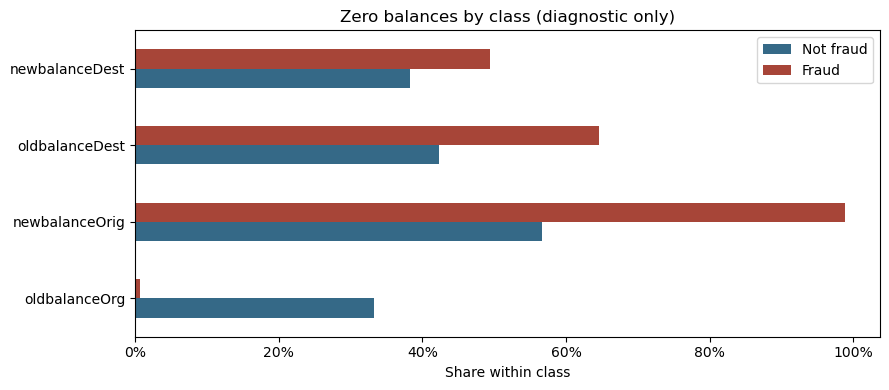

In [5]:
summaries = []
for column in ("amount", *BALANCE_COLUMNS):
    values = dev[column]
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outside = ~values.between(lower, upper)
    summaries.append({
        "field": column, "lower_bound": lower, "upper_bound": upper,
        "flagged_rows": int(outside.sum()), "flagged_pct": 100 * outside.mean(),
        "flagged_fraud_rows": int(dev.loc[outside, "isFraud"].sum()),
    })
display(pd.DataFrame(summaries).round(4))

balance_zeros = dev.loc[:, BALANCE_COLUMNS].eq(0).groupby(dev["isFraud"]).mean().T
balance_zeros.columns = ["Not fraud", "Fraud"]
ax = balance_zeros.plot.barh(figsize=(9, 4), color=["#356987", "#a74538"])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Zero balances by class (diagnostic only)", xlabel="Share within class", ylabel="")
ax.figure.tight_layout()
plt.show()

## 5. What is known before authorization?

| Field | Decision | Why |
|---|---|---|
| `amount`, `type` | **Use** | They are part of the transaction request. Amount must be finite and non-negative; type must be a known category. |
| `step` | Exclude as a model input | It is an absolute hour in this simulation. Use it to order the split, not as a proxy for when this simulator injects particular behavior. A real event timestamp needs its own contract. |
| `oldbalanceOrg`, `oldbalanceDest` | Exclude | A real pre-authorization ledger might provide snapshots. These CSV columns are excluded under the dataset publisher's balance warning; merchant destinations also do not have genuine balance coverage. |
| `newbalanceOrig`, `newbalanceDest` | Exclude | They are outcome-side fields in this CSV, and are not reliably known before authorization. Do not derive balance deltas or mismatch features from them. |
| `isFlaggedFraud` | Audit only | It is a simulator business-rule output. We have not verified that an equivalent independent rule runs upstream of scoring. |
| `nameOrig`, `nameDest` | Exclude | Identifiers are not portable risk features. Future account-history features would need point-in-time joins and separate evaluation. |
| `isFraud` | Label only | It is the simulated outcome, unavailable as a scoring input. |

**Handoff:** Notebook 04 models every validated row without IQR filtering. It compares two safe baselines with a same-period, diagnostic-only model that uses the historical 12 features.